In [4]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
import pathlib

In [5]:
%matplotlib widget

Google Earth section


I first started by identifing the pixel resolution in meters, using one of the images as sample

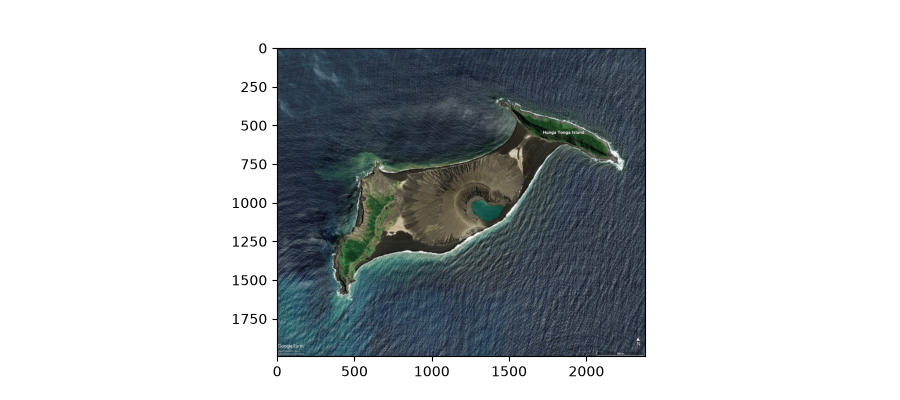

In [ ]:
# Load one of the white light images as a sample
sample = mpimg.imread('sentinel-data/White_light/2020Nov.jpg')
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(sample)
plt.show()

From the image, I gathered tha length, in pixel, of the image scale, that I used to compute the size of the pixel

In [22]:
# Compute the size of the pixel side
pixel_m2 = (600/ (2375.3 - 2067.8))**2
print(pixel_m2)

3.8072575847709693


From here I identified the area in m^2 for the Google Earth images of ~ 3.81 m^2 per pixel

Afterward, I plotted the differences between channels of the sample, to identify the best one to compute the land area over time

In [23]:
# Compute the channels and the channel differences
cr = sample[:, :, 0] # Red channel
cg = sample[:, :, 1] # Green channel
cb = sample[:, :, 2] # Blue channel
rg_diff = cr - cg # Red-Green difference
rb_diff = cr  - cb # Red-Blue difference
gb_diff = cg - cb # Green-Blue difference

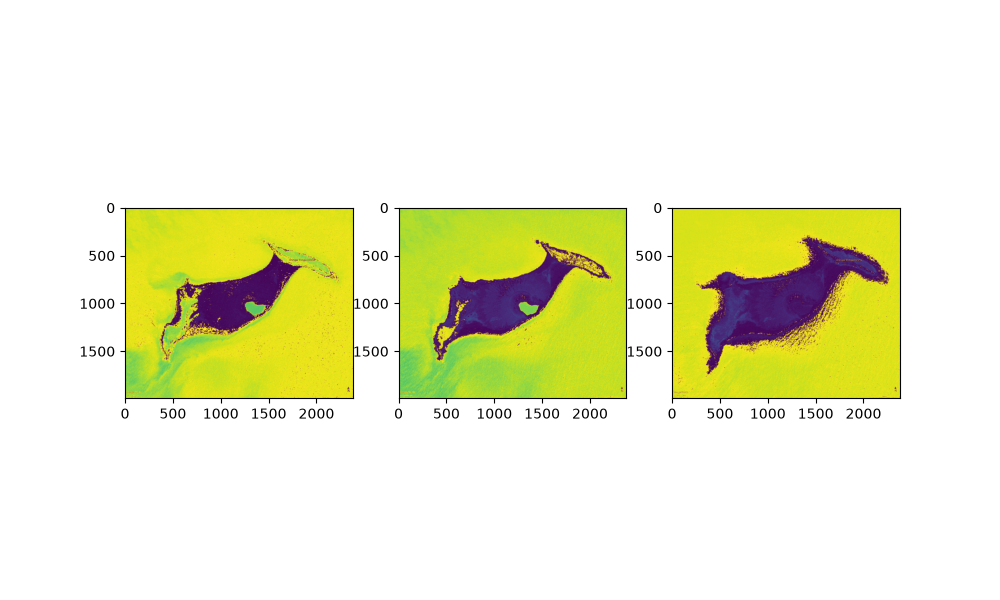

In [24]:
# Plot them side by side for an easy comparison
fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(10, 6))
ax1.imshow(rg_diff)
ax2.imshow(rb_diff)
ax3.imshow(gb_diff)
plt.show()

Of the 3 differences, the Green-Blue channel seems to be the one to include the most of the land area, including the vegetation (which the Red-Blue and Red-Green difference exclude).
From the plots, the land pixel have a value below 100, which I later used to mask them out.

Once I defined this, I expanded the computation to all the images, to ensure that the images are all behaving in the same way.

In [ ]:
# Assign the path to all the white light images
here = pathlib.Path('.')
wl_files = list((here / 'sentinel-data/White_light').rglob('*.jpg'))

[WindowsPath('sentinel-data/White_light/2014Feb.jpg'), WindowsPath('sentinel-data/White_light/2016May.jpg'), WindowsPath('sentinel-data/White_light/2020Nov.jpg'), WindowsPath('sentinel-data/White_light/2021Dec.jpg'), WindowsPath('sentinel-data/White_light/2022Jan.jpg'), WindowsPath('sentinel-data/White_light/2023Oct.jpg')]


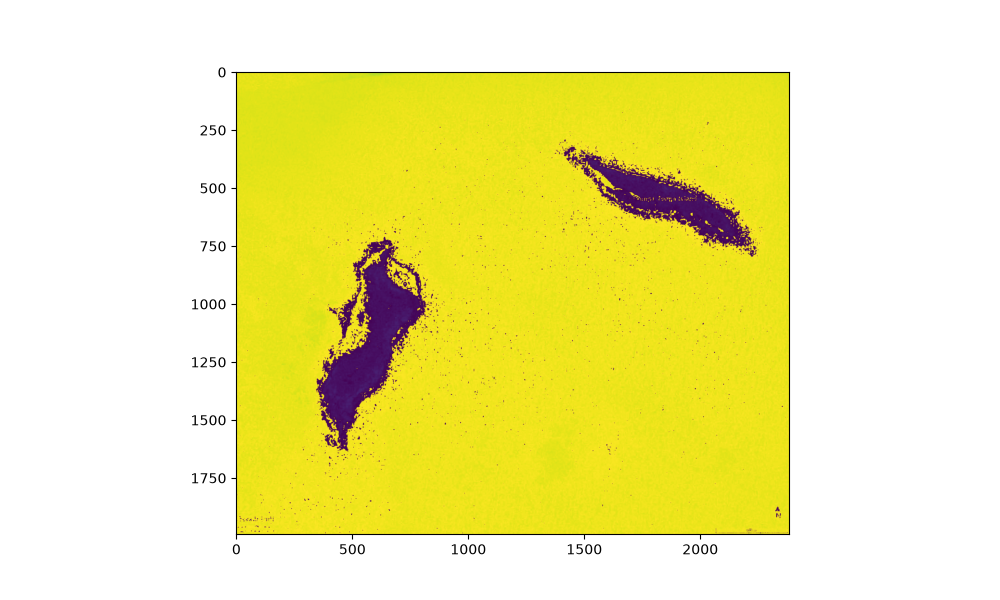

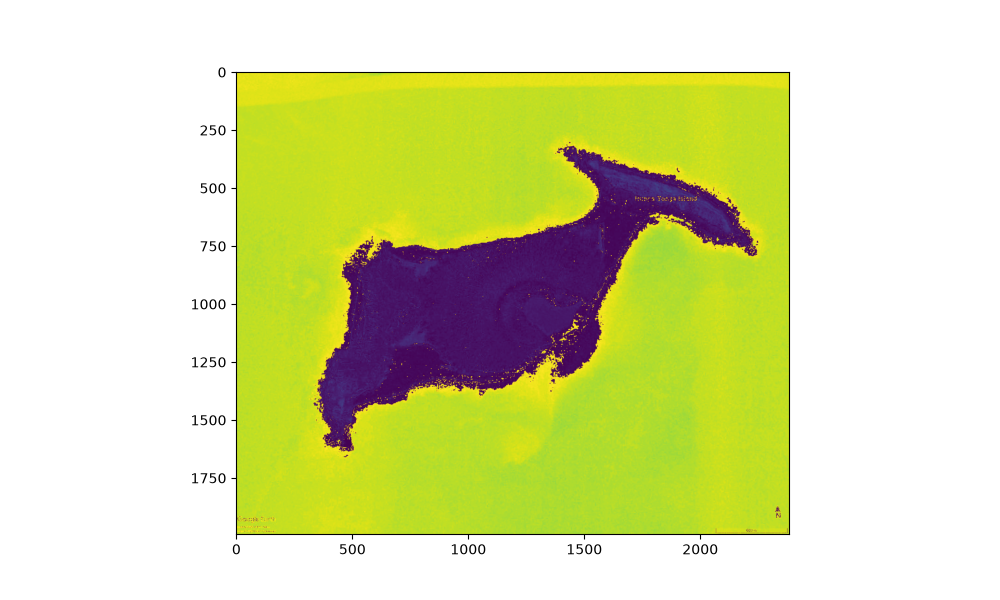

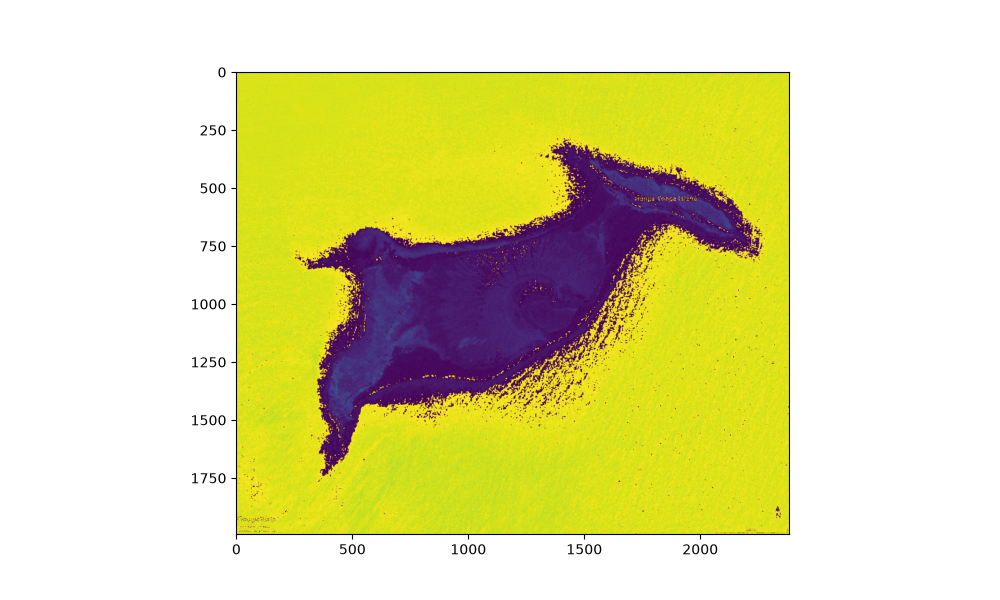

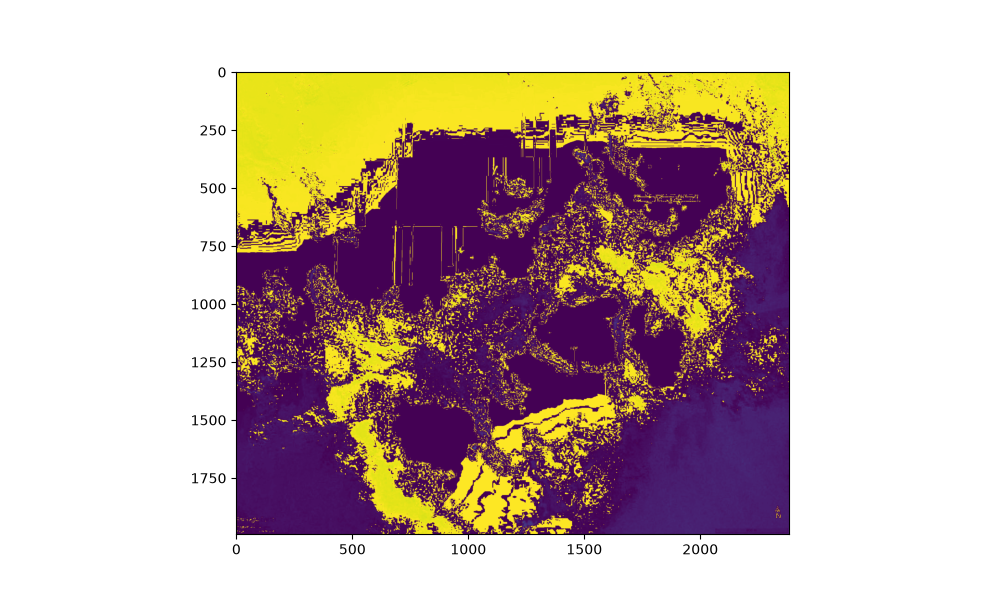

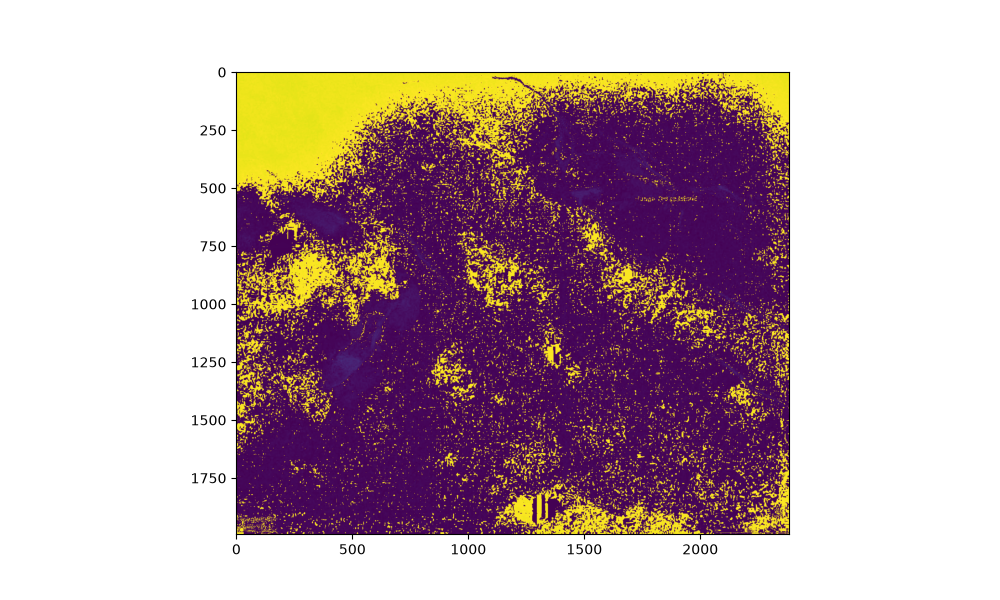

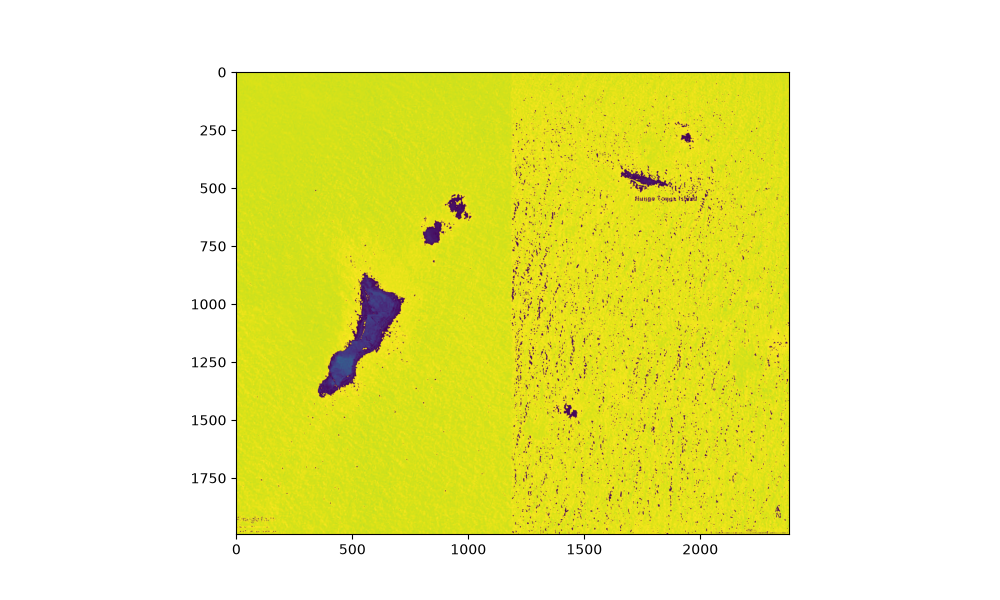

In [25]:
for file in wl_files:
    wl = mpimg.imread(file)
    # Only loading the Green and Blue channels,
    # as I'm only using the Green-Blue difference
    cg = wl[:, :, 1]
    cb = wl[:, :, 2]
    gb_diff = cg - cb
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(gb_diff)
    plt.show()

With the output of the previous function, I observed that the images from Dec 2021 and Jan 2022 are not viable to be analysed, due to a lot of clouds confusing the analysis, so I later excluded them from the land vs time analysis.

I then proceeded to write a function to compute the total land area over time, create a plot to visualize the change, and save the plot in the processed data

In [ ]:
def land_over_time(wl_images, dates):
    """
    Takes the white light images path and date label, and save the plot
    of the total land area as a function of time
    
    Parameters:
    -----------
    wl_images: path
            path item of the white light images
        dates: string
            labels of the images dates

    Returns:
    -----------
    saved plot 
    """
    total_land_area = [] # Array to store the land area values

    for file in wl_images:
        wl = mpimg.imread(file)
        
        cg = wl[:, :, 1]
        cb = wl[:, :, 2]
        gb_diff = cg - cb

        pixel_area_m2 = (600 / (2375.3 - 2067.8)) ** 2

        land_pixels = gb_diff < 100 # Mask land pixels

        total_land_pixel = np.sum(land_pixels)
        # Convert area from m^2 to km^2
        area_km2 = (total_land_pixel * pixel_area_m2) / 1000000
        total_land_area.append(area_km2)
    
    # As the images with index 3 and 4 have lots of clouds, the resulting images
    # were excluded from the final analysis
    
    del total_land_area[3:5] # This line is to be modified 
                             # if the wl files are different
    
    plt.close('all')
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(dates, total_land_area, marker='o', color='brown', linewidth=2.5, markersize=8)
    ax.set_title("Land area over time", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel("Surface (km^2)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.show()
    # Save the plot in sentinel-processed folder for later
    plt.savefig("sentinel-processed/land_vs_time.jpg", dpi=300, bbox_inches='tight')

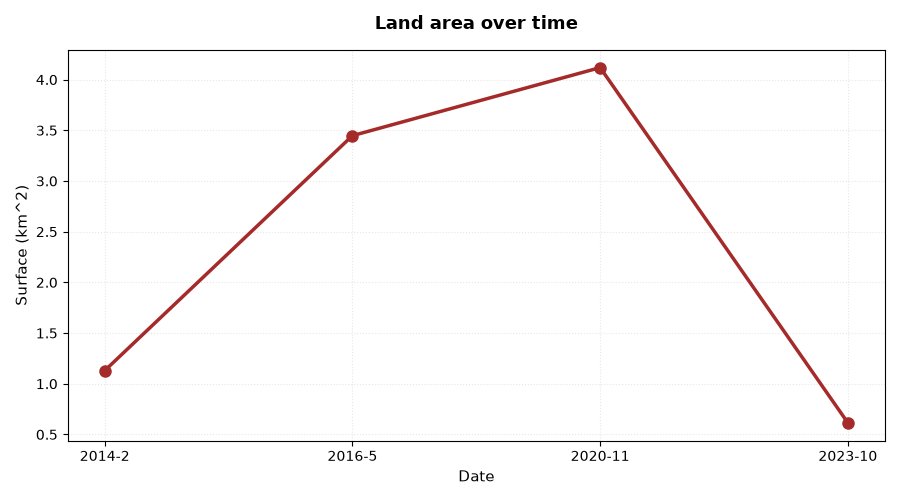

In [14]:
date_labels = ['2014-2', '2016-5', '2020-11', '2023-10']
land_over_time(wl_files, date_labels)

Now for the Sentinel 2 section

Here I first started by computing the pixel resolution in km^2, using a sample file at first

In [26]:
# Assign a sample Sentinel2 image for the pixel resolution computation
file = 'sentinel-data/S2_2017-07-12/Sentinel-2_L2A_False_color.tiff'

In [27]:
# Extract the pixel resolution and bounds from the sample file
with rasterio.open(file) as src:
    resolution = src.res
    bounds = src.bounds

In [28]:
# Resolutions in angular fraction
res_x = resolution[0]
res_y = resolution[1]

length_p = np.abs(bounds.left-bounds.right) / res_x
height_p = np.abs(bounds.top-bounds.bottom) / res_y

# Print the two sides measurments to double check
print(f'The image is {length_p} by {height_p } pixels')

# Conversion from angle to kilometer
conv_const = 40075 / 360 # Using a mean value for the Earth 
                         # circumference in km^2, to convert
                         # the pixel reolution

res_x = res_x * conv_const
res_y = res_y * conv_const

lenght_m = length_p * res_x
height_m = height_p * res_y
image_area = lenght_m * height_m

print(f'The total area of the image is {image_area} km^2')

# Computed pixel area in m^2, to be compared
# to the expected one of 100 m^2
pixels = length_p * height_p
pixel_km2 = image_area / pixels
pixel_m2 = pixel_km2 * 1e6
print(f"The computed pixel resolution is {pixel_m2} m^2")

The image is 529.0 by 314.0 pixels
The total area of the image is 15.565376776654007 km^2
The computed pixel resolution is 93.70749266524994 m^2


After I computed the pixel area in km, I started to load the files to see how to compute the vegetation index

In [29]:
# Assign the paths to the Sentinel images
files_2017 = sorted(list((here / 'sentinel-data/S2_2017-07-12').rglob('*.tiff')))
files_2018 = sorted(list((here / 'sentinel-data/S2_2018-07-12').rglob('*.tiff')))
files_2019 = sorted(list((here / 'sentinel-data/S2_2019-07-12').rglob('*.tiff')))

Then, I proceeded to make a function to compute the vegetation area as a function of time, using two methods to later compare them. I first compute the vegetation index from the B4 and B8 files; then I loaded the one from the NDVI file. I finally identified the pixels that had vegetation (>0.3 for the band index, <0.05 for the NDVI file), summed them and plotted them as a function of time, to compare the area identified by the two.

In [30]:
def veg_over_time(files, dates):
    """
    Takes the Sentinel2 file paths and date label, and save the plot
    of the total vegetation area as a function of time
        
    Parameters:
    -----------
    filess: array
        array of the Sentinel2 images paths
    dates: string
        labels of the images dates
    
    Returns:
    -----------
    saved plot 
    """
    
    total_veg_area = []
    ndvi_area = []
    for file_list in files:

        # For each year, open the necessery files (B4, B8 and NDVI)
        with rasterio.open(file_list[3]) as src4, \
             rasterio.open(file_list[7]) as src8, \
             rasterio.open(file_list[17]) as src_ndvi:
            
            b4 = src4.read(1).astype('float32')
            b8 = src8.read(1).astype('float32')
            ndvi = src_ndvi.read(1).astype('float32')
            
            
            # Compute the pixel resolution
            res_x, res_y = src4.res
            conv_const = 40075 / 360
            res_x = res_x * conv_const
            res_y = res_y * conv_const
            pixel_area_km2 = res_x * res_y
            
        # Vegetation area from Bands
        veg_ind = (b8 - b4) / (b8 + b4)
        veg_ind = np.nan_to_num(veg_ind, nan=-1.0) # Replace any nan value
        veg_pixels = veg_ind > 0.3 # Mask the non-vegetation pixels
        total_veg_pixels = np.sum(veg_pixels)
        area_km2 = total_veg_pixels * pixel_area_km2

        # Vegetation area from the ndvi file
        ndvi_pixels = ndvi < 0.05
        total_ndvi_pixels = np.sum(ndvi_pixels)
        ndvi_area_km2 = total_ndvi_pixels * pixel_area_km2
    
        # Save the area results to plot them
        total_veg_area.append(area_km2)
        ndvi_area.append(ndvi_area_km2)

    plt.close('all')
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(dates, total_veg_area, marker='o', color='green', linewidth=2.5,
            markersize=8, label='Bands vegetation index')
    ax.plot(dates, ndvi_area, marker='s', color='darkgreen', linewidth=2.5,
            markersize=8, linestyle='--', label='NDVI file')
    ax.set_title("Vegetation area over time", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel("Surface (km^2)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.savefig("sentinel-processed/vegetation_vs_time.jpg", dpi=300, bbox_inches='tight')

C:\Users\march\AppData\Local\Temp\ipykernel_28804\3028612827.py:27: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b4 = src4.read(1).astype('float32')
C:\Users\march\AppData\Local\Temp\ipykernel_28804\3028612827.py:28: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b8 = src8.read(1).astype('float32')
C:\Users\march\AppData\Local\Temp\ipykernel_28804\3028612827.py:29: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  ndvi = src_ndvi.read(1).astype('float32')
C:\Users\march\AppData\Local\Temp\ipykernel_28804\3028612827.py:40: RuntimeWarning: invalid value encountered in divide
  veg_ind = (b8 

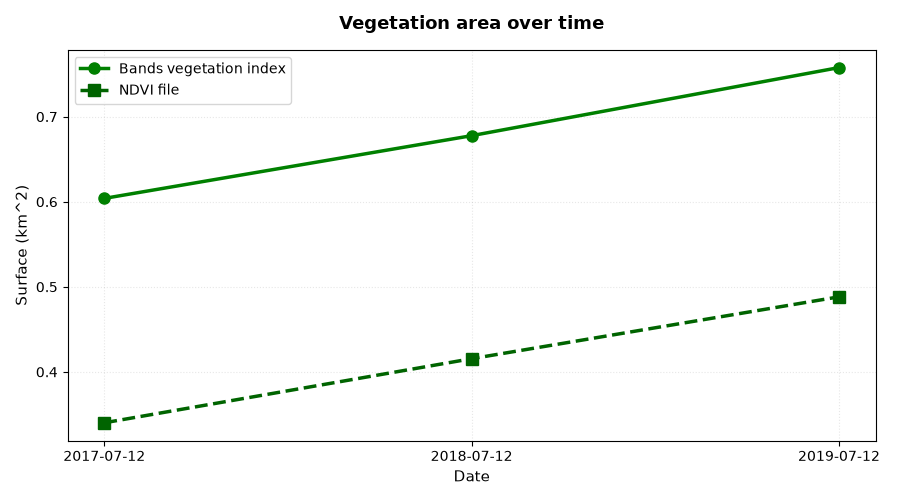

In [31]:
all_files = [files_2017, files_2018, files_2019]
date_labels = ['2017-07-12', '2018-07-12', '2019-07-12']

veg_over_time(all_files, date_labels)